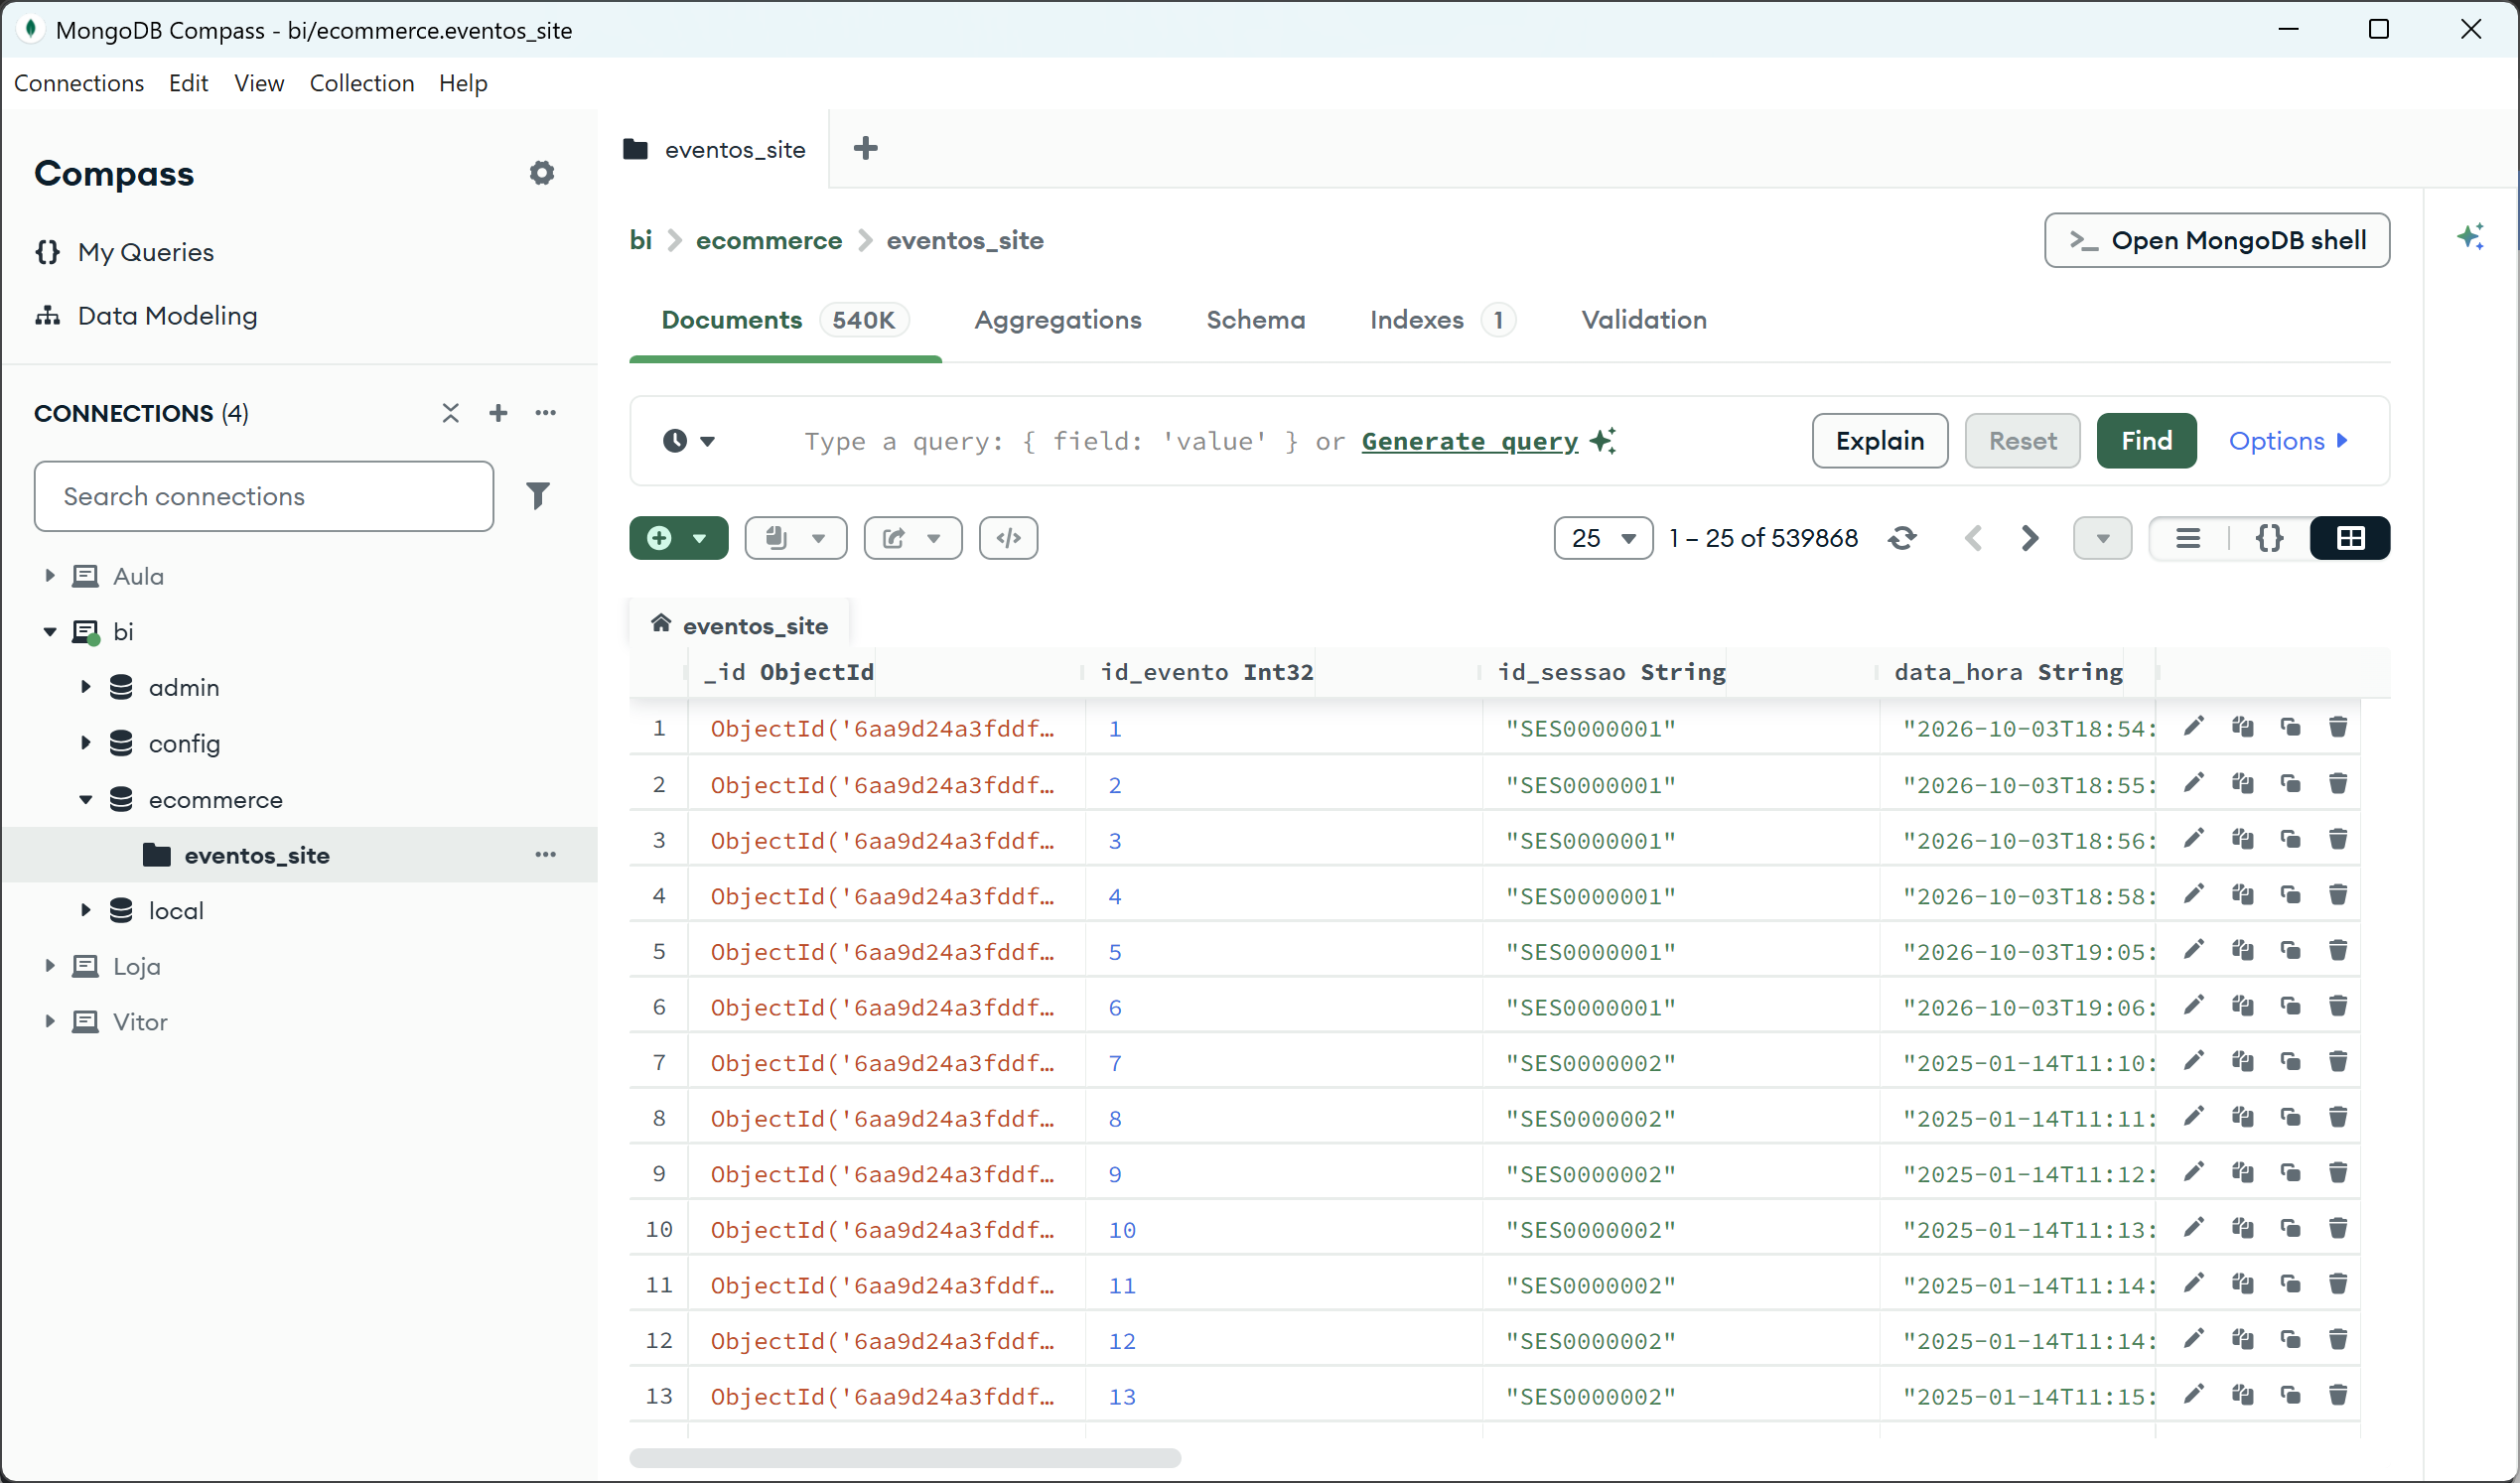
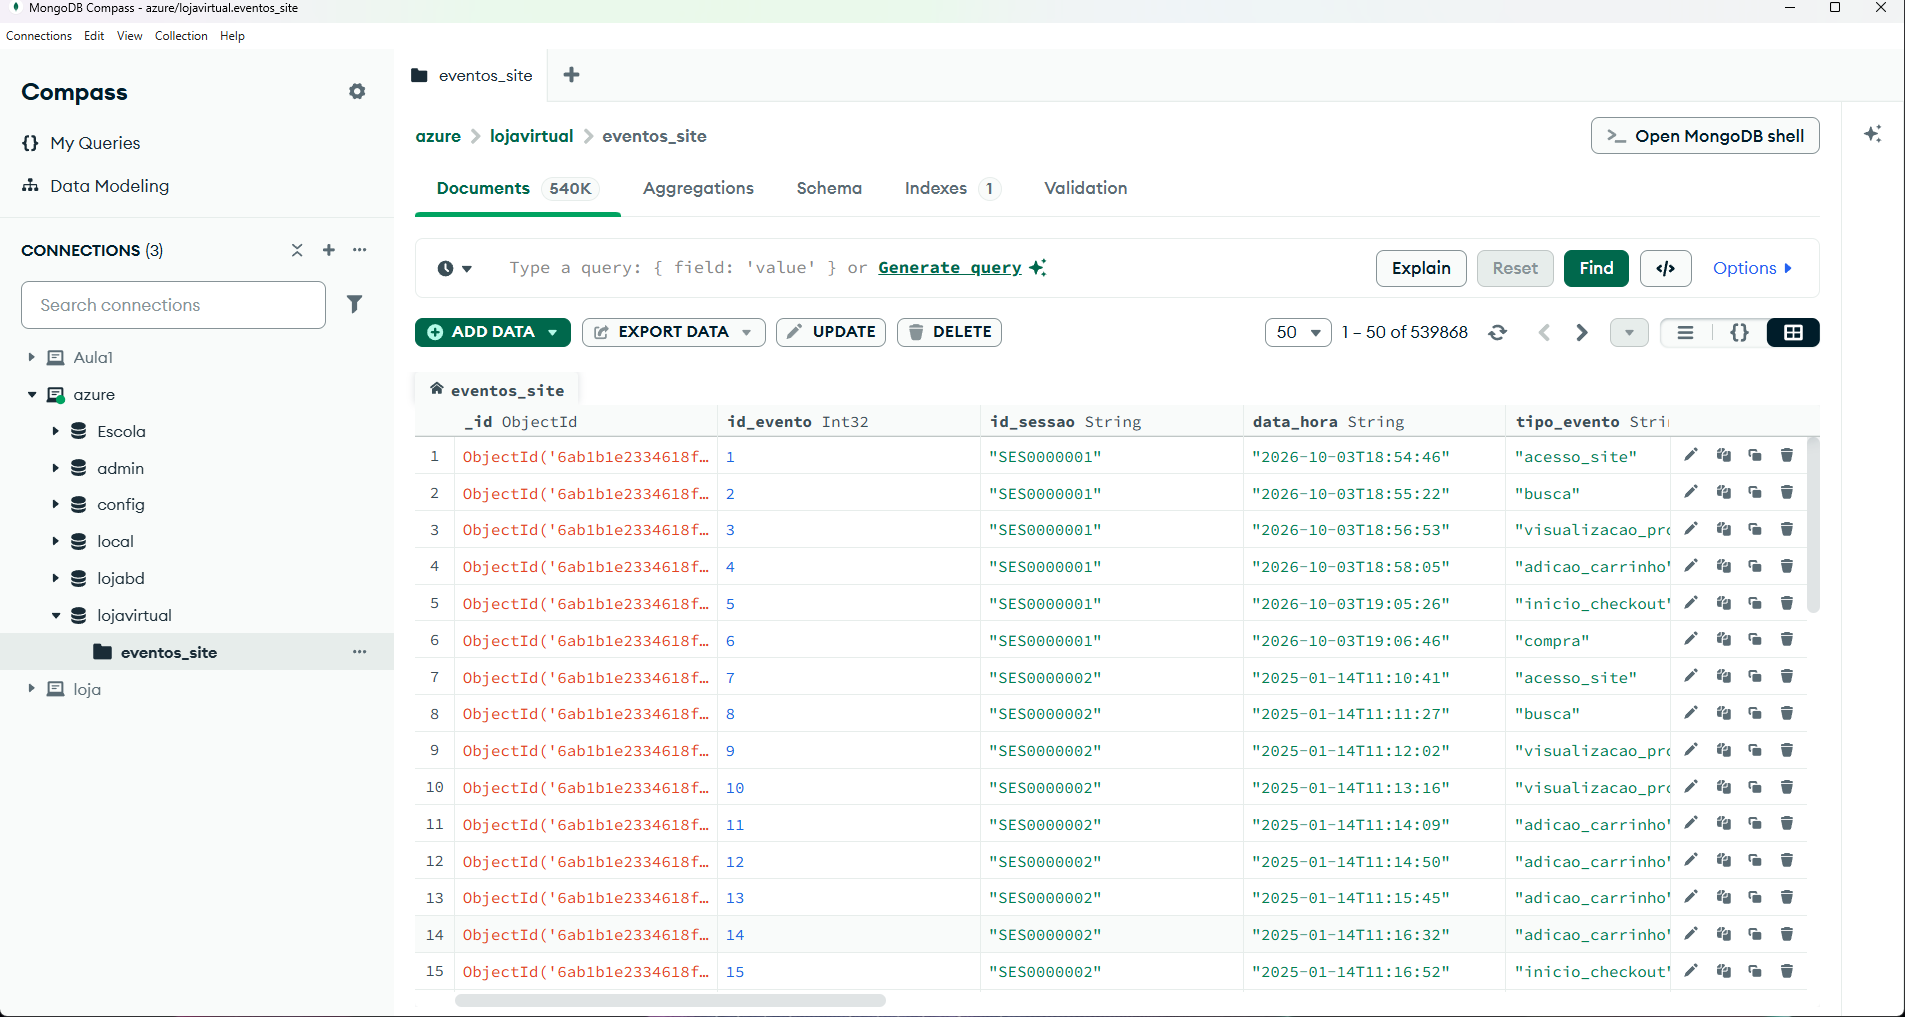

pip install pymongo

In [18]:
import os
from dotenv import load_dotenv
from pymongo import MongoClient

load_dotenv()

mongo_uri = os.getenv("MONGO_URI")
mongo_database = os.getenv("MONGO_DATABASE")

if not mongo_uri or not mongo_database:
    raise ValueError("Configurações do MongoDB não encontradas no .env")

cliente = MongoClient(mongo_uri)

db = cliente[mongo_database]

colecao = db["eventos_site"]

print("Conexão realizada com sucesso!")
print("Total de documentos:", colecao.count_documents({}))

Conexão realizada com sucesso!
Total de documentos: 539868


In [19]:
import pandas as pd

documentos = list(colecao.find())

df = pd.DataFrame(documentos)

print(df.dtypes)

_id                object
id_evento           int64
id_sessao             str
data_hora             str
tipo_evento           str
dispositivo           str
origem_trafego        str
id_cliente        float64
termo_busca           str
id_produto        float64
quantidade        float64
valor_carrinho    float64
id_pedido         float64
dtype: object


In [20]:
display(df.head())

,_id,id_evento,id_sessao,data_hora,tipo_evento,dispositivo,origem_trafego,id_cliente,termo_busca,id_produto,quantidade,valor_carrinho,id_pedido
0,6aa9d24a3fddf9888bc7008d,1,SES0000001,2026-10-03T18:54:46,acesso_site,mobile,Instagram,3681.0,NaN,NaN,NaN,NaN,NaN
1,6aa9d24a3fddf9888bc7008e,2,SES0000001,2026-10-03T18:55:22,busca,mobile,Instagram,3681.0,Televisores,NaN,NaN,NaN,NaN
2,6aa9d24a3fddf9888bc7008f,3,SES0000001,2026-10-03T18:56:53,visualizacao_produto,mobile,Instagram,3681.0,NaN,6.0,NaN,NaN,NaN
3,6aa9d24a3fddf9888bc70090,4,SES0000001,2026-10-03T18:58:05,adicao_carrinho,mobile,Instagram,3681.0,NaN,6.0,1.0,429.15,NaN
4,6aa9d24a3fddf9888bc70091,5,SES0000001,2026-10-03T19:05:26,inicio_checkout,mobile,Instagram,3681.0,NaN,NaN,NaN,429.15,NaN


In [21]:
import os
from dotenv import load_dotenv
from azure.storage.filedatalake import DataLakeServiceClient

load_dotenv()

connection_string = os.getenv("AZURE_STORAGE_CONNECTION_STRING")

if connection_string:
    print("Credencial carregada com sucesso!")
else:
    print("Credencial não encontrada.")

Credencial carregada com sucesso!


In [22]:
servico_azure = DataLakeServiceClient.from_connection_string(
    connection_string
)

container_azure = servico_azure.get_file_system_client("bronze")

print(container_azure.get_file_system_properties()["name"])

bronze


In [23]:
df["_id"] = df["_id"].astype(str)

In [24]:
df.to_parquet(
    "eventos_site.parquet",
    index=False,
    engine="pyarrow" #indica qual biblioteca o Pandas deve utilizar para gerar o arquivo Parquet.
)

print("Arquivo Parquet gerado com sucesso!")

Arquivo Parquet gerado com sucesso!


In [25]:
arquivo_azure = container_azure.get_file_client(
    "mongodb/eventos_site/eventos_site.parquet"
)

with open("eventos_site.parquet", "rb") as arquivo_local:
    arquivo_azure.upload_data(
        arquivo_local,
        overwrite=True
    )

# O "rb" significa Read Binary, ou seja, leitura em modo binário.

print("Arquivo enviado ao Azure com sucesso!")

Arquivo enviado ao Azure com sucesso!


In [26]:
arquivo_azure = container_azure.get_file_client(
    "mongodb/eventos_site/eventos_site.parquet"
)

propriedades = arquivo_azure.get_file_properties()

print("Arquivo:", propriedades.name)
print("Tamanho (bytes):", propriedades.size)

Arquivo: mongodb/eventos_site/eventos_site.parquet
Tamanho (bytes): 13793325


In [17]:
from io import BytesIO
# BytesIO é uma classe do Python que permite armazenar dados binários diretamente na memória RAM, como se fossem um arquivo.

arquivo_azure = container_azure.get_file_client(
    "mongodb/eventos_site/eventos_site.parquet"
)

conteudo = arquivo_azure.download_file().readall()

dados_azure = pd.read_parquet(BytesIO(conteudo))

display(dados_azure.head(10))

,_id,id_evento,id_sessao,data_hora,tipo_evento,dispositivo,origem_trafego,id_cliente,termo_busca,id_produto,quantidade,valor_carrinho,id_pedido
0,6aa9d24a3fddf9888bc7008d,1,SES0000001,2026-10-03T18:54:46,acesso_site,mobile,Instagram,3681.0,NaN,NaN,NaN,NaN,NaN
1,6aa9d24a3fddf9888bc7008e,2,SES0000001,2026-10-03T18:55:22,busca,mobile,Instagram,3681.0,Televisores,NaN,NaN,NaN,NaN
2,6aa9d24a3fddf9888bc7008f,3,SES0000001,2026-10-03T18:56:53,visualizacao_produto,mobile,Instagram,3681.0,NaN,6.0,NaN,NaN,NaN
3,6aa9d24a3fddf9888bc70090,4,SES0000001,2026-10-03T18:58:05,adicao_carrinho,mobile,Instagram,3681.0,NaN,6.0,1.0,429.15,NaN
4,6aa9d24a3fddf9888bc70091,5,SES0000001,2026-10-03T19:05:26,inicio_checkout,mobile,Instagram,3681.0,NaN,NaN,NaN,429.15,NaN
5,6aa9d24a3fddf9888bc70092,6,SES0000001,2026-10-03T19:06:46,compra,mobile,Instagram,3681.0,NaN,NaN,NaN,429.15,1.0
6,6aa9d24a3fddf9888bc70093,7,SES0000002,2025-01-14T11:10:41,acesso_site,mobile,Google,5306.0,NaN,NaN,NaN,NaN,NaN
7,6aa9d24a3fddf9888bc70094,8,SES0000002,2025-01-14T11:11:27,busca,mobile,Google,5306.0,Smart,NaN,NaN,NaN,NaN
8,6aa9d24a3fddf9888bc70095,9,SES0000002,2025-01-14T11:12:02,visualizacao_produto,mobile,Google,5306.0,NaN,298.0,NaN,NaN,NaN
9,6aa9d24a3fddf9888bc70096,10,SES0000002,2025-01-14T11:13:16,visualizacao_produto,mobile,Google,5306.0,NaN,6.0,NaN,NaN,NaN
